# Assignment 3: PCA, SVD and LDA on the ORL Face Dataset

**Objective:** Apply three classical linear dimensionality-reduction techniques to the ORL (Olivetti) face database and compare them.

| Technique | Type | Idea |
|---|---|---|
| **PCA** | Unsupervised | Project onto directions of maximum variance (eigenfaces) |
| **SVD** | Unsupervised | Factorise the centred data matrix `X = U S Vᵀ`; gives the same subspace as PCA and low-rank approximations |
| **LDA** | Supervised | Project onto directions that maximise between-class / within-class scatter (Fisherfaces) |




## 1. Imports and Setup

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

In [ ]:
LOCAL_ORL_DIR = None   

def load_orl_local(root, size=(64, 64)):
    from PIL import Image
    X, y = [], []
    for s in range(1, 41):
        for i in range(1, 11):
            path = os.path.join(root, f"s{s}", f"{i}.pgm")
            img = Image.open(path).convert("L").resize(size[::-1])
            X.append(np.asarray(img, dtype=np.float64).ravel() / 255.0)
            y.append(s - 1)
    return np.array(X), np.array(y)

if LOCAL_ORL_DIR:
    IMG_SHAPE = (64, 64)
    X, y = load_orl_local(LOCAL_ORL_DIR, IMG_SHAPE)
else:
    from sklearn.datasets import fetch_olivetti_faces
    faces = fetch_olivetti_faces(shuffle=False)
    X, y = faces.data, faces.target
    IMG_SHAPE = (64, 64)

n_samples, n_features = X.shape
n_classes = len(np.unique(y))
print(f"Images: {n_samples}, features (pixels): {n_features}, subjects: {n_classes}")
print(f"Pixel range: [{X.min():.2f}, {X.max():.2f}]")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\bhavi\scikit_learn_data
Images: 400, features (pixels): 4096, subjects: 40
Pixel range: [0.00, 1.00]


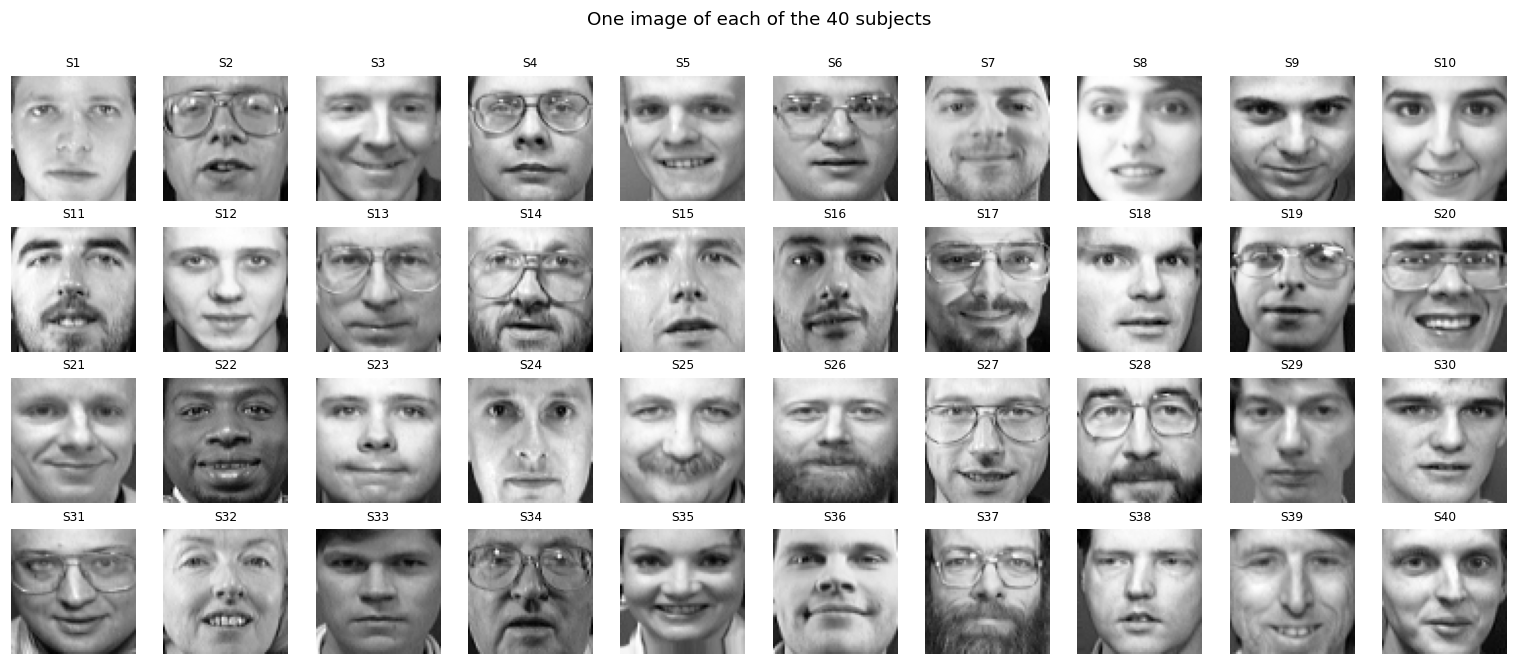

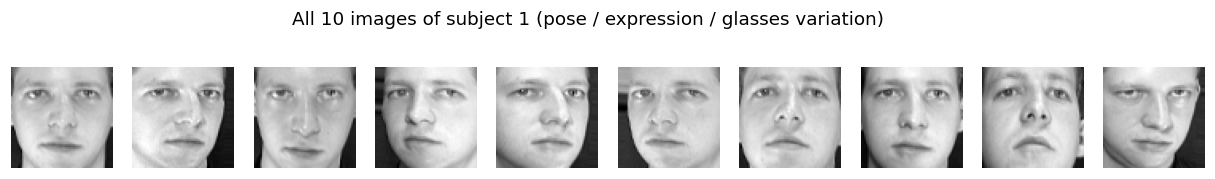

In [3]:
fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i * 10].reshape(IMG_SHAPE), cmap="gray")
    ax.set_title(f"S{y[i*10]+1}", fontsize=8)
    ax.axis("off")
plt.suptitle("One image of each of the 40 subjects", y=1.0)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(IMG_SHAPE), cmap="gray"); ax.axis("off")
plt.suptitle("All 10 images of subject 1 (pose / expression / glasses variation)")
plt.show()

## 3. Train / Test Split
Stratified 70/30 split so every subject appears in both sets (7 train and 3 test images per subject).

Train: (280, 4096)  Test: (120, 4096)


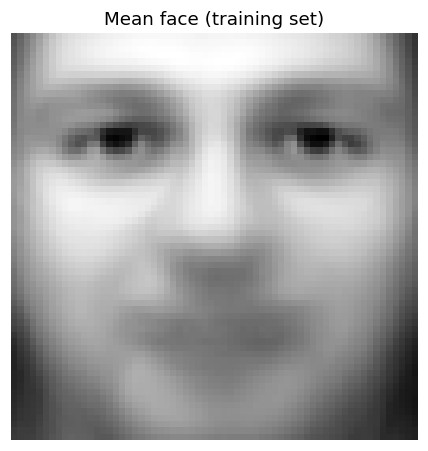

Baseline 1-NN accuracy on raw pixels (4096 dims): 0.9250


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

mean_face = X_train.mean(axis=0)
plt.imshow(mean_face.reshape(IMG_SHAPE), cmap="gray"); plt.title("Mean face (training set)"); plt.axis("off"); plt.show()

def knn_acc(Ztr, Zte, k=1):
    clf = KNeighborsClassifier(n_neighbors=k).fit(Ztr, y_train)
    return accuracy_score(y_test, clf.predict(Zte))

base_acc = knn_acc(X_train, X_test)
print(f"Baseline 1-NN accuracy on raw pixels ({n_features} dims): {base_acc:.4f}")

## 4. Principal Component Analysis (PCA)

PCA finds an orthonormal basis that maximises variance. Steps:
1. Centre the data: `Xc = X - mean`
2. Covariance matrix `C = XcᵀXc / (n-1)` (4096x4096)
3. Eigen-decomposition `C v = λ v`; sort by descending λ
4. Project onto the top-k eigenvectors: `Z = Xc V_k`

Because `n (=280) << d (=4096)`, we use the *Turk-Pentland trick*: eigen-decompose the small `n x n` Gram matrix `XcXcᵀ`
and map its eigenvectors back to pixel space (`v = Xcᵀ u / ||Xcᵀ u||`). This gives the same non-zero eigenpairs much faster.

In [5]:
# ---- PCA from scratch ----
Xc = X_train - mean_face
n = Xc.shape[0]

gram = (Xc @ Xc.T) / (n - 1)                 # n x n
eigvals, U = np.linalg.eigh(gram)
idx = np.argsort(eigvals)[::-1]
eigvals, U = eigvals[idx], U[:, idx]

keep = eigvals > 1e-10                       # drop numerically-zero components
eigvals, U = eigvals[keep], U[:, keep]

V = Xc.T @ U                                 # d x r
V /= np.linalg.norm(V, axis=0)               # unit-length eigenfaces
print("Number of non-zero principal components:", V.shape[1])

# ---- Compare with sklearn ----
pca_full = PCA(svd_solver="full").fit(X_train)
r = 10
print("\nTop-5 eigenvalues  (scratch):", np.round(eigvals[:5], 5))
print("Top-5 eigenvalues  (sklearn):", np.round(pca_full.explained_variance_[:5], 5))
print("Max |difference| in first 10 eigenvalues:", np.abs(eigvals[:r] - pca_full.explained_variance_[:r]).max())

Number of non-zero principal components: 279

Top-5 eigenvalues  (scratch): [19.61857 10.22351  6.45576  3.89387  2.90111]
Top-5 eigenvalues  (sklearn): [19.61857 10.2235   6.45576  3.89387  2.90111]
Max |difference| in first 10 eigenvalues: 4.2915344e-06


90% variance needs 59 components
95% variance needs 104 components
99% variance needs 200 components


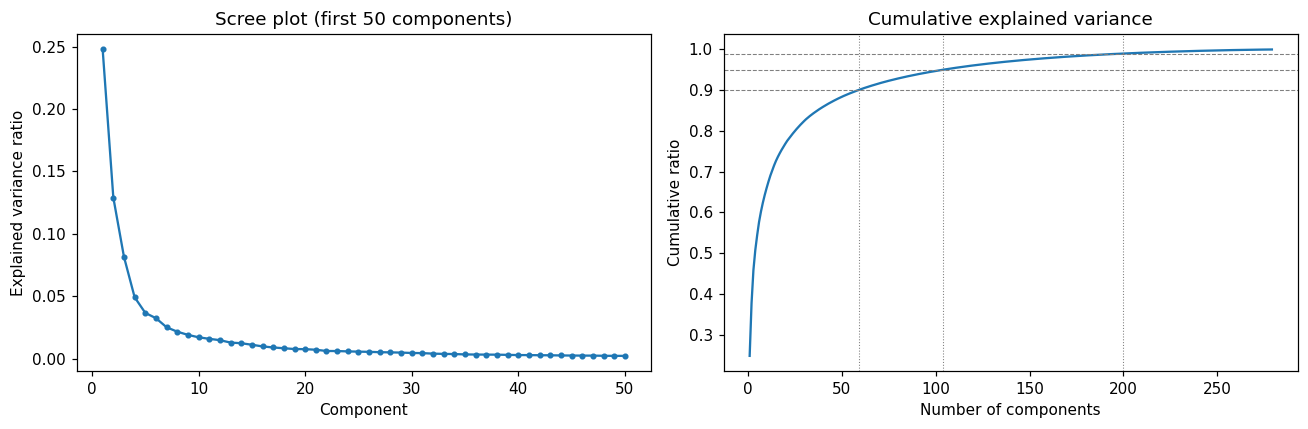

In [6]:
# ---- Explained variance ----
evr = eigvals / eigvals.sum()
cum = np.cumsum(evr)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 51), evr[:50], "o-", ms=3)
ax[0].set_title("Scree plot (first 50 components)"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum)
for thr in (0.90, 0.95, 0.99):
    k = int(np.searchsorted(cum, thr) + 1)
    ax[1].axhline(thr, ls="--", c="gray", lw=0.7); ax[1].axvline(k, ls=":", c="gray", lw=0.7)
    print(f"{int(thr*100)}% variance needs {k} components")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative ratio")
plt.tight_layout(); plt.show()

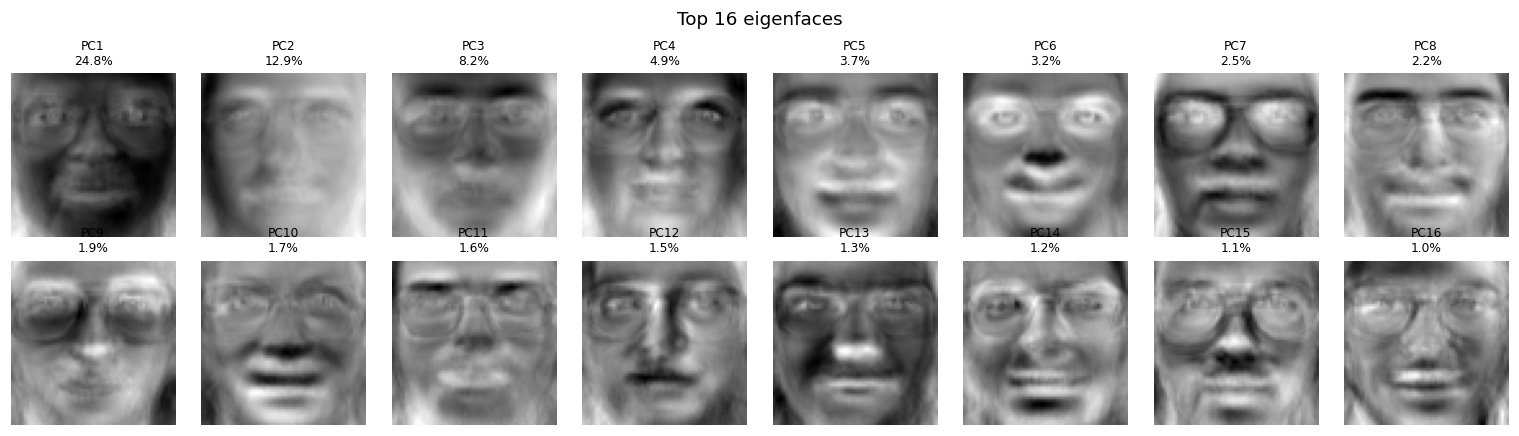

In [7]:
# ---- Eigenfaces ----
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(V[:, i].reshape(IMG_SHAPE), cmap="gray")
    ax.set_title(f"PC{i+1}\n{evr[i]*100:.1f}%", fontsize=8); ax.axis("off")
plt.suptitle("Top 16 eigenfaces"); plt.tight_layout(); plt.show()

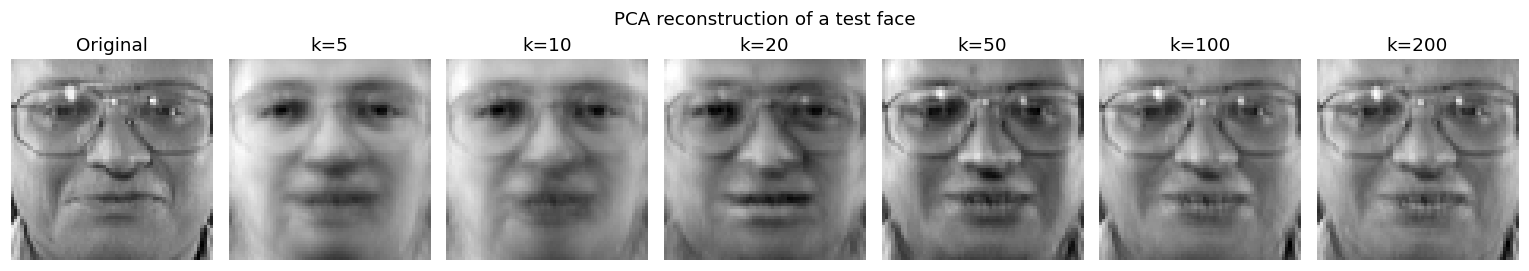

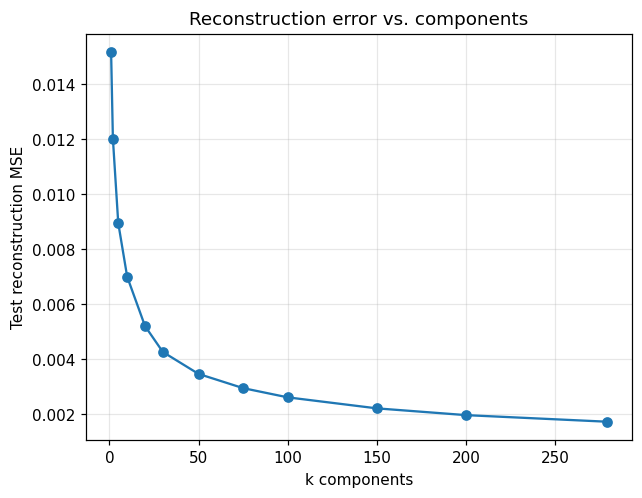

In [8]:
# ---- Reconstruction with different numbers of components ----
def pca_reconstruct(x, k):
    z = (x - mean_face) @ V[:, :k]
    return mean_face + z @ V[:, :k].T

ks = [5, 10, 20, 50, 100, 200]
sample = X_test[0]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(14, 2.5))
axes[0].imshow(sample.reshape(IMG_SHAPE), cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks):
    ax.imshow(pca_reconstruct(sample, k).reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"k={k}"); ax.axis("off")
plt.suptitle("PCA reconstruction of a test face"); plt.tight_layout(); plt.show()

# reconstruction MSE vs k
ks_range = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, V.shape[1]]
mse = [np.mean((X_test - np.array([pca_reconstruct(x, k) for x in X_test])) ** 2) for k in ks_range]
plt.plot(ks_range, mse, "o-"); plt.xlabel("k components"); plt.ylabel("Test reconstruction MSE")
plt.title("Reconstruction error vs. components"); plt.grid(alpha=.3); plt.show()

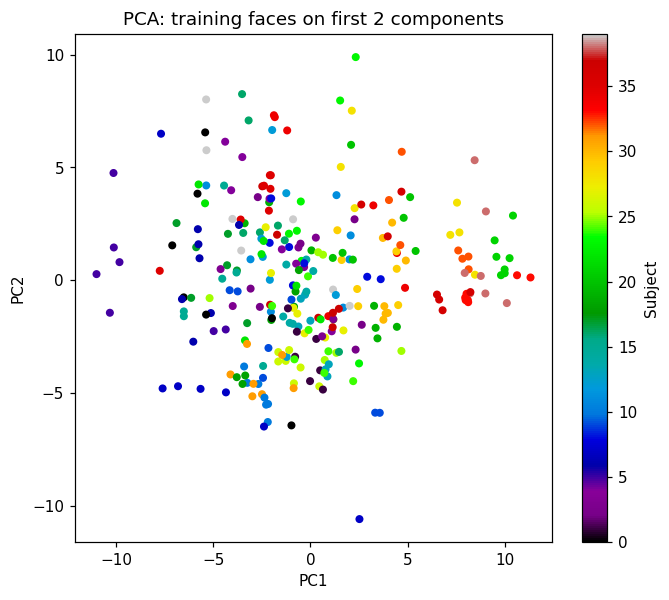

In [9]:
# ---- 2-D and 3-D PCA projections ----
Z2 = (X_train - mean_face) @ V[:, :2]
plt.figure(figsize=(7, 6))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=y_train, cmap="nipy_spectral", s=18)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA: training faces on first 2 components")
plt.colorbar(sc, label="Subject"); plt.show()

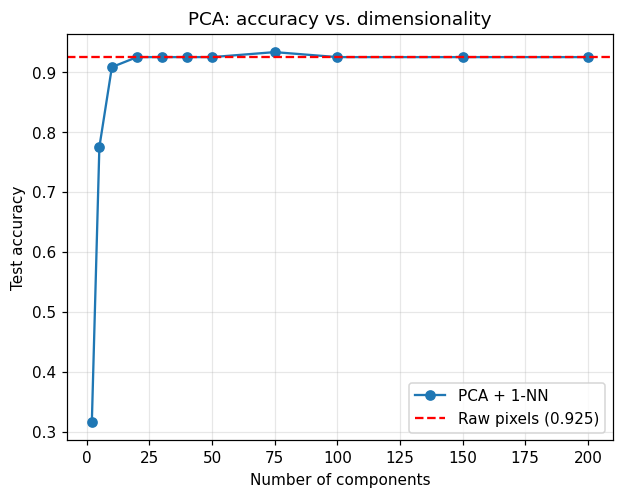

,components,accuracy
0,2,0.3167
1,5,0.7750
2,10,0.9083
3,20,0.9250
4,30,0.9250
5,40,0.9250
6,50,0.9250
7,75,0.9333
8,100,0.9250
9,150,0.9250


In [10]:
# ---- Classification accuracy vs number of PCA components (1-NN) ----
ks_cls = [2, 5, 10, 20, 30, 40, 50, 75, 100, 150, 200]
pca_accs = []
for k in ks_cls:
    Ztr = (X_train - mean_face) @ V[:, :k]
    Zte = (X_test - mean_face) @ V[:, :k]
    pca_accs.append(knn_acc(Ztr, Zte))

plt.plot(ks_cls, pca_accs, "o-", label="PCA + 1-NN")
plt.axhline(base_acc, color="r", ls="--", label=f"Raw pixels ({base_acc:.3f})")
plt.xlabel("Number of components"); plt.ylabel("Test accuracy"); plt.title("PCA: accuracy vs. dimensionality")
plt.legend(); plt.grid(alpha=.3); plt.show()
pd.DataFrame({"components": ks_cls, "accuracy": np.round(pca_accs, 4)})

In [11]:
best_k_pca = ks_cls[int(np.argmax(pca_accs))]
best_acc_pca = max(pca_accs)
print(f"Best PCA setting: k={best_k_pca}, accuracy={best_acc_pca:.4f}")

Best PCA setting: k=75, accuracy=0.9333


## 5. Singular Value Decomposition (SVD)

For the centred data matrix `Xc` (n x d):

`Xc = U Σ Vᵀ`

* columns of `V` = principal directions (same as PCA eigenvectors, up to sign)
* eigenvalues of the covariance matrix: `λᵢ = σᵢ² / (n-1)`
* projections: `Z = Xc V_k = U_k Σ_k`
* best rank-k approximation (Eckart-Young): `X_k = U_k Σ_k V_kᵀ`

In [12]:
U_svd, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("U:", U_svd.shape, " S:", S.shape, " Vt:", Vt.shape)

# --- Equivalence with PCA ---
svd_eigvals = S ** 2 / (n - 1)
print("\nTop-5 eigenvalues from SVD :", np.round(svd_eigvals[:5], 5))
print("Top-5 eigenvalues from PCA :", np.round(eigvals[:5], 5))

# Compare directions up to sign
cos = np.abs(np.sum(Vt[:10].T * V[:, :10], axis=0))
print("|cos| between SVD and PCA directions (first 10):", np.round(cos, 4))

U: (280, 280)  S: (280,)  Vt: (280, 4096)

Top-5 eigenvalues from SVD : [19.61857 10.2235   6.45576  3.89387  2.90111]
Top-5 eigenvalues from PCA : [19.61857 10.22351  6.45576  3.89387  2.90111]
|cos| between SVD and PCA directions (first 10): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


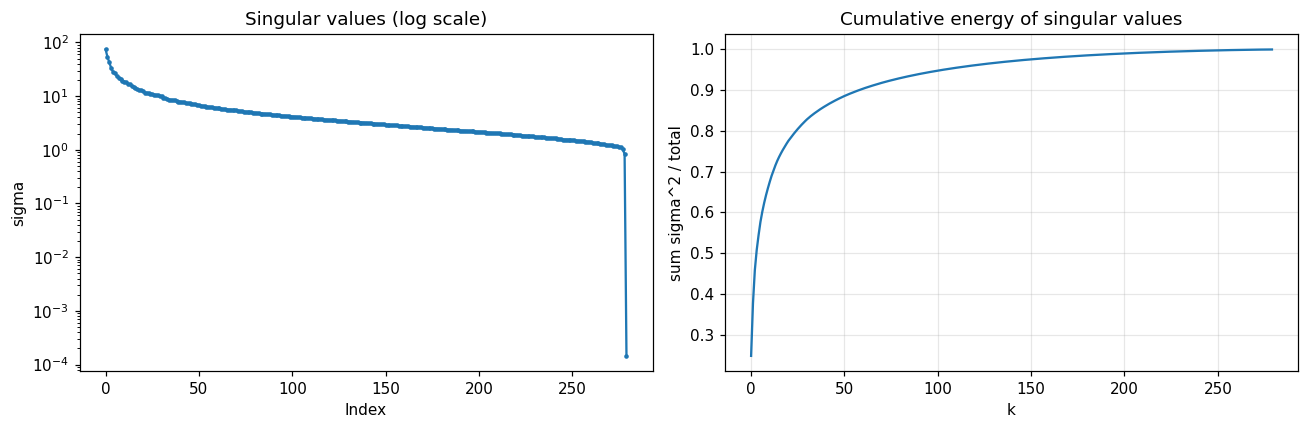

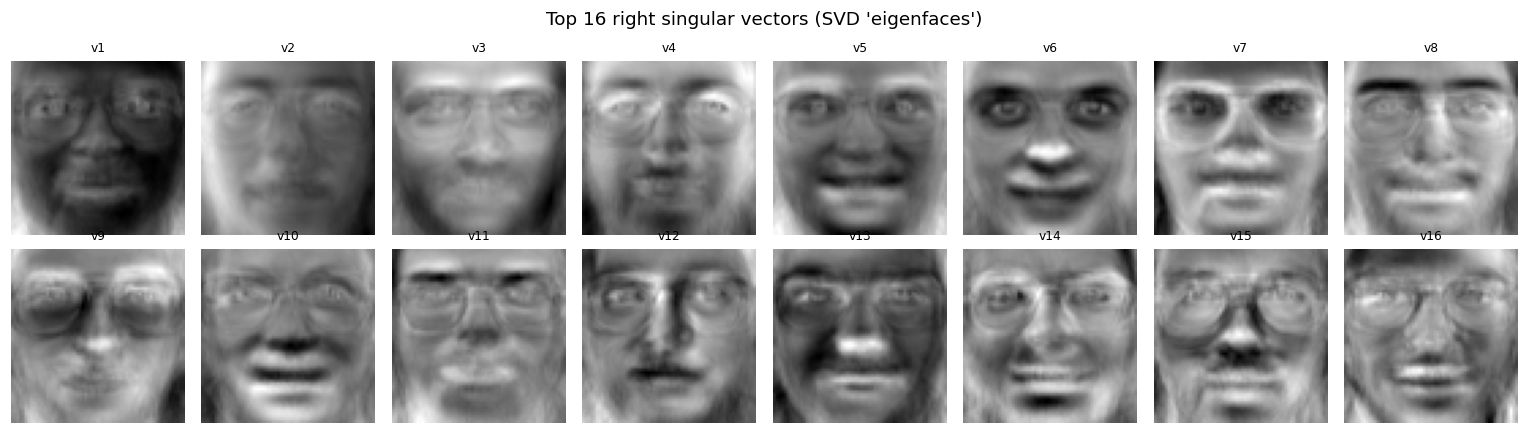

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(S, "o-", ms=2); ax[0].set_yscale("log")
ax[0].set_title("Singular values (log scale)"); ax[0].set_xlabel("Index"); ax[0].set_ylabel("sigma")
energy = np.cumsum(S ** 2) / np.sum(S ** 2)
ax[1].plot(energy); ax[1].set_title("Cumulative energy of singular values")
ax[1].set_xlabel("k"); ax[1].set_ylabel("sum sigma^2 / total"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Vt[i].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"v{i+1}", fontsize=8); ax.axis("off")
plt.suptitle("Top 16 right singular vectors (SVD 'eigenfaces')"); plt.tight_layout(); plt.show()

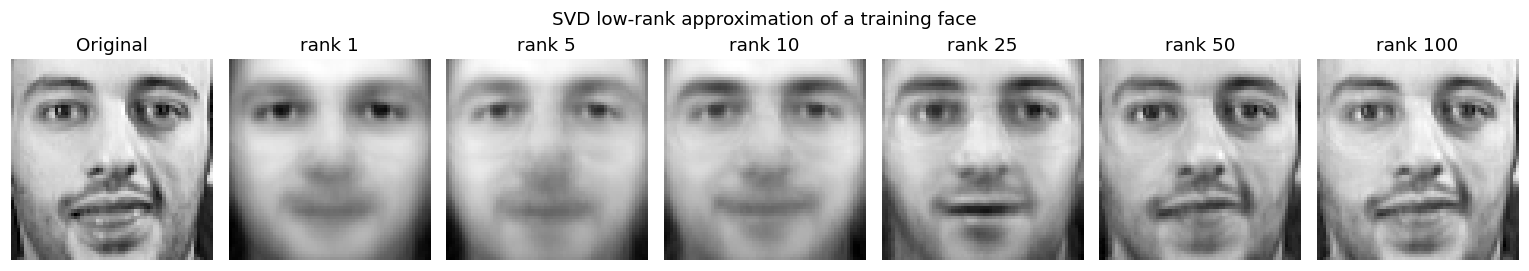

,rank k,relative error,energy kept,compression ratio
0,5,0.6751,0.5443,52.40
1,10,0.5835,0.6595,26.20
2,20,0.4809,0.7688,13.10
3,50,0.3410,0.8837,5.24
4,100,0.2297,0.9473,2.62
5,200,0.0997,0.9901,1.31


In [14]:
# ---- Low-rank approximation ----
def svd_lowrank(k):
    return mean_face + (U_svd[:, :k] * S[:k]) @ Vt[:k]

ks_show = [1, 5, 10, 25, 50, 100]
idx_img = 0
fig, axes = plt.subplots(1, len(ks_show) + 1, figsize=(14, 2.5))
axes[0].imshow(X_train[idx_img].reshape(IMG_SHAPE), cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks_show):
    ax.imshow(svd_lowrank(k)[idx_img].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"rank {k}"); ax.axis("off")
plt.suptitle("SVD low-rank approximation of a training face"); plt.tight_layout(); plt.show()

# Relative Frobenius error and compression ratio
rows = []
for k in [5, 10, 20, 50, 100, 200]:
    rel_err = np.sqrt(1 - np.sum(S[:k] ** 2) / np.sum(S ** 2))
    stored = k * (n + n_features + 1)
    rows.append([k, round(rel_err, 4), round(1 - rel_err ** 2, 4), round(n * n_features / stored, 2)])
pd.DataFrame(rows, columns=["rank k", "relative error", "energy kept", "compression ratio"])

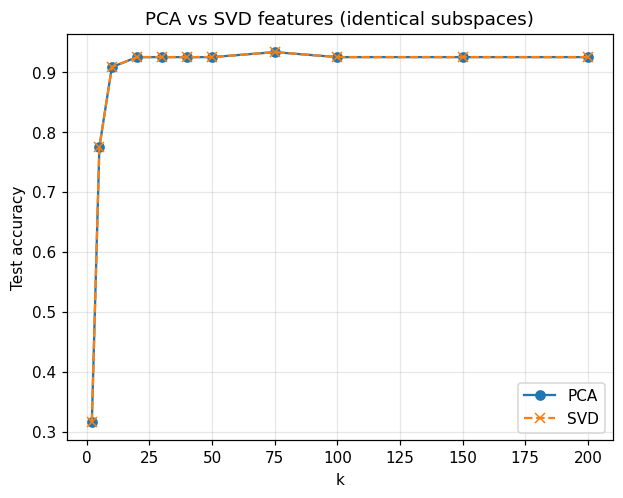

Best SVD setting: k=75, accuracy=0.9333
Max accuracy difference PCA vs SVD: 0.0


In [15]:
# ---- Classification with SVD features ----
svd_accs = []
for k in ks_cls:
    Ztr = Xc @ Vt[:k].T                       # = U_k * S_k
    Zte = (X_test - mean_face) @ Vt[:k].T
    svd_accs.append(knn_acc(Ztr, Zte))

plt.plot(ks_cls, pca_accs, "o-", label="PCA")
plt.plot(ks_cls, svd_accs, "x--", label="SVD")
plt.xlabel("k"); plt.ylabel("Test accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("PCA vs SVD features (identical subspaces)"); plt.show()

best_k_svd = ks_cls[int(np.argmax(svd_accs))]; best_acc_svd = max(svd_accs)
print(f"Best SVD setting: k={best_k_svd}, accuracy={best_acc_svd:.4f}")
print("Max accuracy difference PCA vs SVD:", np.max(np.abs(np.array(pca_accs) - np.array(svd_accs))))

## 6. Linear Discriminant Analysis (LDA / Fisherfaces)

LDA maximises the Fisher criterion

`J(W) = |Wᵀ S_B W| / |Wᵀ S_W W|`

where `S_W` is the within-class scatter and `S_B` the between-class scatter. The solution is given by the top eigenvectors of `S_W⁻¹ S_B`; there are at most **C - 1 = 39** useful discriminant directions.

**Small-sample-size problem:** the number of training images (280) is far smaller than the number of pixels (4096), so `S_W` is singular. The standard fix (Belhumeur et al., *Fisherfaces*) is to first reduce dimensionality with PCA to at most `N - C` dimensions and then apply LDA.

In [16]:
# ---- Step 1: PCA to N - C dims (or fewer) ----
N_PCA = min(n - n_classes, 100)
V_pca = V[:, :N_PCA]
Ptr = (X_train - mean_face) @ V_pca
Pte = (X_test - mean_face) @ V_pca
print(f"PCA stage: {n_features} -> {N_PCA} dims")

# ---- Step 2: LDA from scratch ----
def lda_scratch(Z, labels, n_comp):
    classes = np.unique(labels)
    mu = Z.mean(axis=0)
    d = Z.shape[1]
    Sw = np.zeros((d, d)); Sb = np.zeros((d, d))
    for c in classes:
        Zc = Z[labels == c]
        mc = Zc.mean(axis=0)
        Sw += (Zc - mc).T @ (Zc - mc)
        diff = (mc - mu).reshape(-1, 1)
        Sb += len(Zc) * (diff @ diff.T)
    evals, evecs = np.linalg.eig(np.linalg.pinv(Sw) @ Sb)
    order = np.argsort(evals.real)[::-1]
    return evecs[:, order[:n_comp]].real, evals.real[order]

W_lda, lda_evals = lda_scratch(Ptr, y_train, n_classes - 1)
print("Top-5 Fisher eigenvalues:", np.round(lda_evals[:5], 3))

Ltr_s, Lte_s = Ptr @ W_lda, Pte @ W_lda
print(f"LDA (scratch) 1-NN accuracy with {n_classes-1} components: {knn_acc(Ltr_s, Lte_s):.4f}")

PCA stage: 4096 -> 100 dims
Top-5 Fisher eigenvalues: [104.706  52.731  40.315  33.5    28.648]
LDA (scratch) 1-NN accuracy with 39 components: 0.9833


In [17]:
# ---- LDA with sklearn ----
lda = LinearDiscriminantAnalysis(n_components=n_classes - 1, solver="svd")
Ltr = lda.fit_transform(Ptr, y_train)
Lte = lda.transform(Pte)

print("sklearn LDA classifier accuracy (direct)    :", round(lda.score(Pte, y_test), 4))
print("sklearn LDA projection + 1-NN accuracy      :", round(knn_acc(Ltr, Lte), 4))
print("Explained variance ratio (first 5)          :", np.round(lda.explained_variance_ratio_[:5], 4))

sklearn LDA classifier accuracy (direct)    : 0.9833
sklearn LDA projection + 1-NN accuracy      : 0.9833
Explained variance ratio (first 5)          : [0.2111 0.1063 0.0813 0.0675 0.0578]


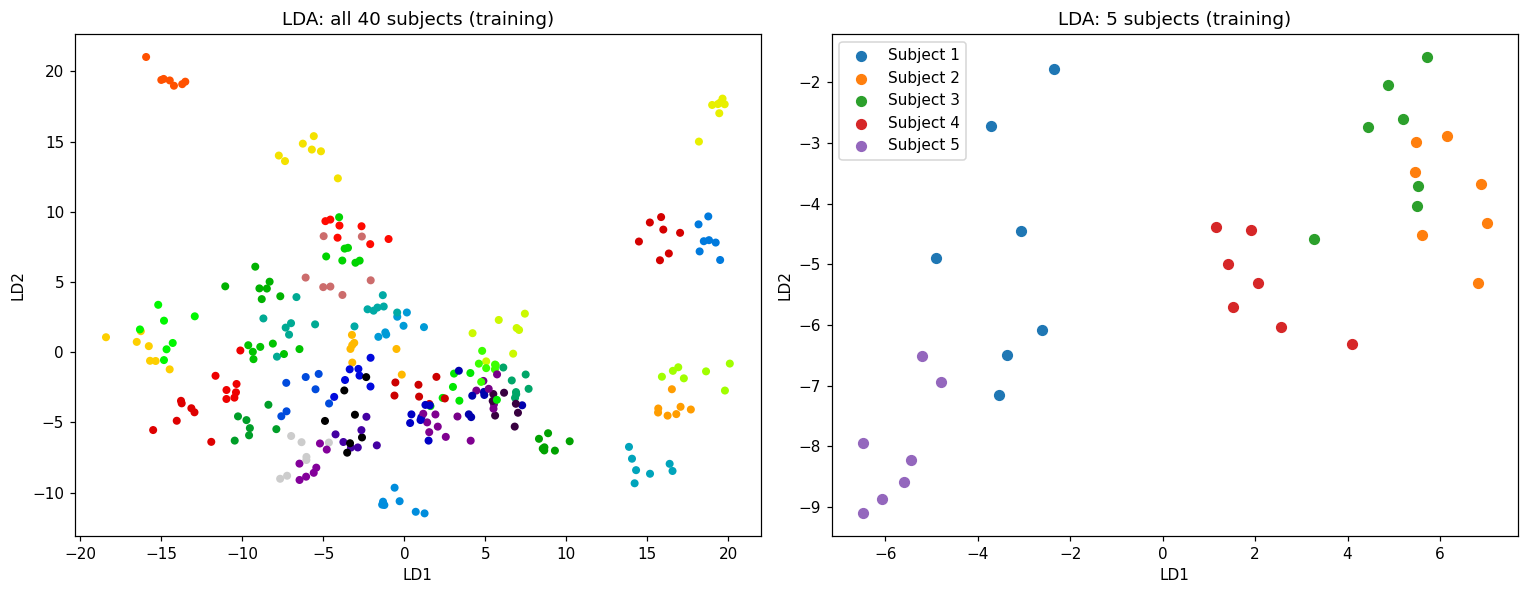

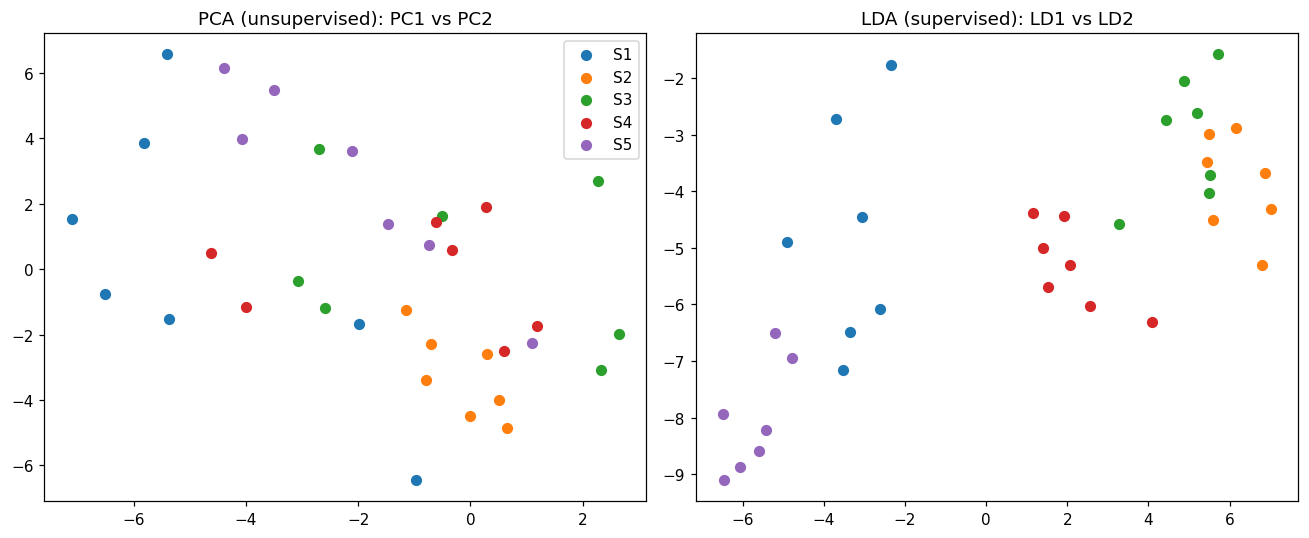

In [18]:
# ---- Visualise LDA projection (5 subjects for clarity, and all subjects) ----
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sc = ax[0].scatter(Ltr[:, 0], Ltr[:, 1], c=y_train, cmap="nipy_spectral", s=18)
ax[0].set_title("LDA: all 40 subjects (training)"); ax[0].set_xlabel("LD1"); ax[0].set_ylabel("LD2")

subset = [0, 1, 2, 3, 4]
for s in subset:
    m = y_train == s
    ax[1].scatter(Ltr[m, 0], Ltr[m, 1], s=40, label=f"Subject {s+1}")
ax[1].set_title("LDA: 5 subjects (training)"); ax[1].set_xlabel("LD1"); ax[1].set_ylabel("LD2"); ax[1].legend()
plt.tight_layout(); plt.show()

# PCA vs LDA 2-D side by side on same 5 subjects
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for s in subset:
    m = y_train == s
    ax[0].scatter(Z2[m, 0], Z2[m, 1], s=40, label=f"S{s+1}")
    ax[1].scatter(Ltr[m, 0], Ltr[m, 1], s=40, label=f"S{s+1}")
ax[0].set_title("PCA (unsupervised): PC1 vs PC2"); ax[1].set_title("LDA (supervised): LD1 vs LD2")
ax[0].legend(); plt.tight_layout(); plt.show()

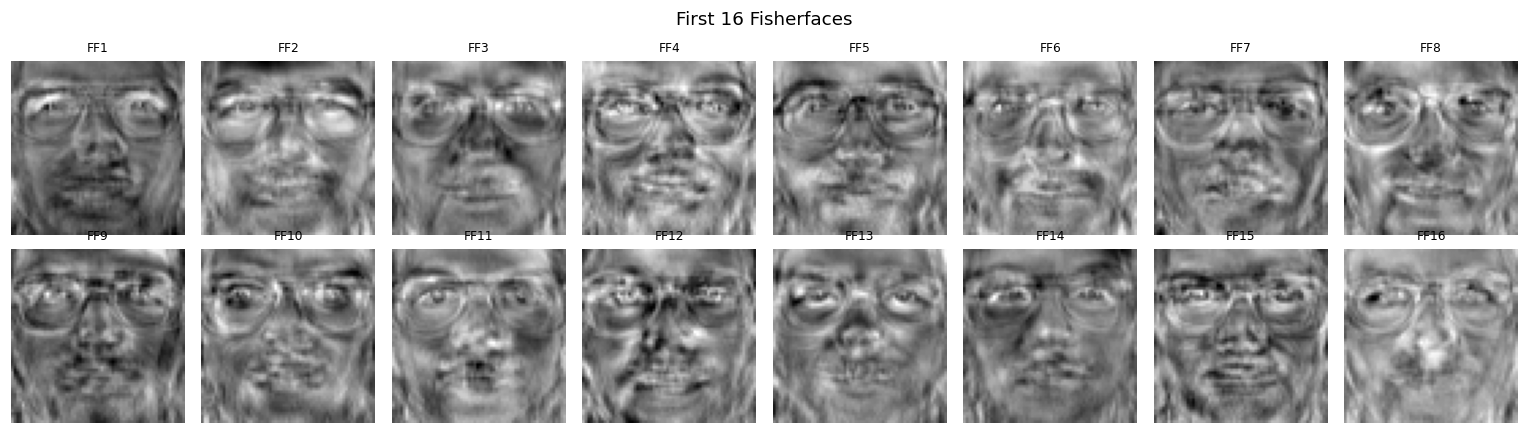

In [19]:
# ---- Fisherfaces: map LDA directions back to pixel space ----
fisherfaces = V_pca @ lda.scalings_[:, :n_classes - 1]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(fisherfaces[:, i].reshape(IMG_SHAPE), cmap="gray"); ax.set_title(f"FF{i+1}", fontsize=8); ax.axis("off")
plt.suptitle("First 16 Fisherfaces"); plt.tight_layout(); plt.show()

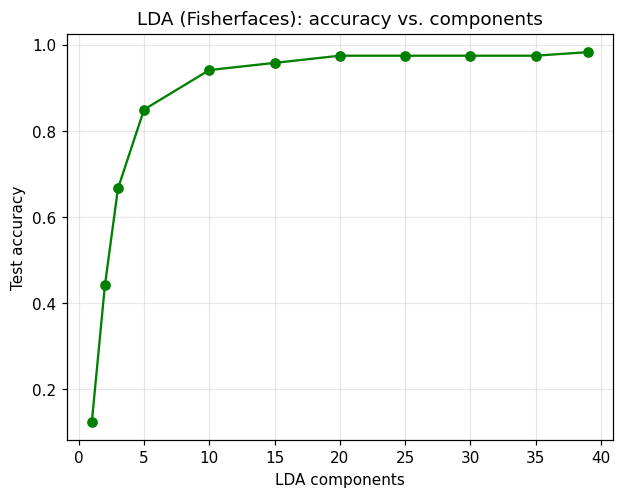

Best LDA setting: k=39, accuracy=0.9833


In [20]:
# ---- Accuracy vs number of LDA components ----
lda_ks = [1, 2, 3, 5, 10, 15, 20, 25, 30, 35, 39]
lda_accs = [knn_acc(Ltr[:, :k], Lte[:, :k]) for k in lda_ks]
plt.plot(lda_ks, lda_accs, "o-", c="green")
plt.xlabel("LDA components"); plt.ylabel("Test accuracy"); plt.title("LDA (Fisherfaces): accuracy vs. components")
plt.grid(alpha=.3); plt.show()
best_k_lda = lda_ks[int(np.argmax(lda_accs))]; best_acc_lda = max(lda_accs)
print(f"Best LDA setting: k={best_k_lda}, accuracy={best_acc_lda:.4f}")

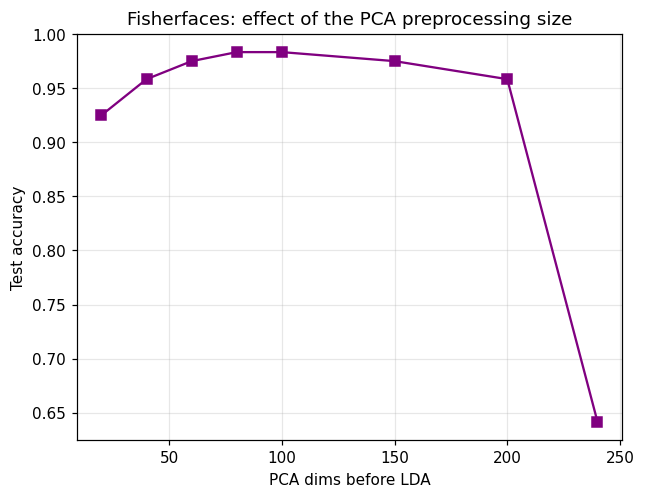

,PCA dims,LDA accuracy
0,20,0.9250
1,40,0.9583
2,60,0.9750
3,80,0.9833
4,100,0.9833
5,150,0.9750
6,200,0.9583
7,240,0.6417


In [21]:
# ---- Sensitivity to the number of PCA dims used before LDA ----
pre_dims = [20, 40, 60, 80, 100, 150, 200, 240]
res = []
for p in pre_dims:
    Ptr_p = (X_train - mean_face) @ V[:, :p]
    Pte_p = (X_test - mean_face) @ V[:, :p]
    m = LinearDiscriminantAnalysis(n_components=min(39, p)).fit(Ptr_p, y_train)
    res.append(m.score(Pte_p, y_test))
plt.plot(pre_dims, res, "s-", c="purple"); plt.xlabel("PCA dims before LDA"); plt.ylabel("Test accuracy")
plt.title("Fisherfaces: effect of the PCA preprocessing size"); plt.grid(alpha=.3); plt.show()
pd.DataFrame({"PCA dims": pre_dims, "LDA accuracy": np.round(res, 4)})

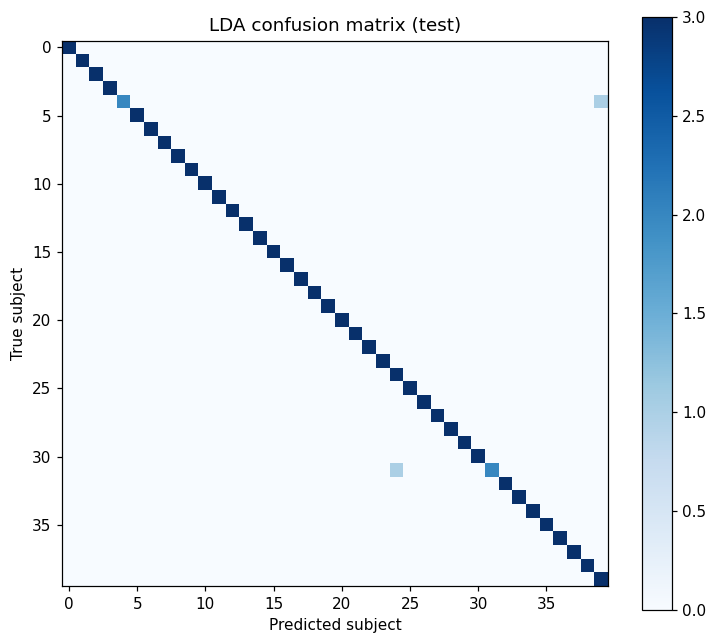

Misclassified test images: 2 of 120


In [22]:
# ---- Confusion matrix and report for the final LDA model ----
y_pred = lda.predict(Pte)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.title("LDA confusion matrix (test)"); plt.xlabel("Predicted subject"); plt.ylabel("True subject"); plt.show()
print("Misclassified test images:", int((y_pred != y_test).sum()), "of", len(y_test))

## 7. Comparison of Methods

,Method,Dimensions,Test accuracy
0,Raw pixels (no reduction),4096,0.9250
1,PCA + 1-NN,75,0.9333
2,SVD + 1-NN,75,0.9333
3,PCA + LDA (Fisherfaces) + 1-NN,39,0.9833


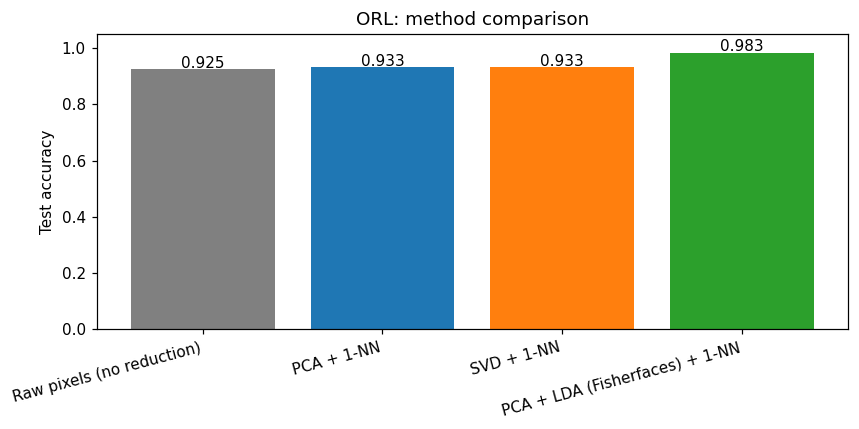

In [23]:
summary = pd.DataFrame([
    ["Raw pixels (no reduction)", n_features, base_acc],
    ["PCA + 1-NN",                best_k_pca, best_acc_pca],
    ["SVD + 1-NN",                best_k_svd, best_acc_svd],
    ["PCA + LDA (Fisherfaces) + 1-NN", best_k_lda, best_acc_lda],
], columns=["Method", "Dimensions", "Test accuracy"])
summary["Test accuracy"] = summary["Test accuracy"].round(4)
display(summary)

plt.figure(figsize=(8, 4))
bars = plt.bar(summary["Method"], summary["Test accuracy"], color=["gray", "tab:blue", "tab:orange", "tab:green"])
for b, a in zip(bars, summary["Test accuracy"]):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.005, f"{a:.3f}", ha="center")
plt.ylim(0, 1.05); plt.ylabel("Test accuracy"); plt.xticks(rotation=15, ha="right")
plt.title("ORL: method comparison"); plt.tight_layout(); plt.show()

In [24]:
# ---- Effect of k (neighbours) and the data split: cross-validated robustness check ----
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pipes = {
    "Raw + 1NN":       make_pipeline(KNeighborsClassifier(1)),
    f"PCA({best_k_pca}) + 1NN":  make_pipeline(PCA(best_k_pca), KNeighborsClassifier(1)),
    "PCA(100) + LDA":  make_pipeline(PCA(100), LinearDiscriminantAnalysis()),
}
cv_rows = []
for name, p in pipes.items():
    accs = []
    for tr, te in skf.split(X, y):
        p.fit(X[tr], y[tr]); accs.append(p.score(X[te], y[te]))
    cv_rows.append([name, np.mean(accs), np.std(accs)])
pd.DataFrame(cv_rows, columns=["Pipeline", "CV mean acc", "CV std"]).round(4)

,Pipeline,CV mean acc,CV std
0,Raw + 1NN,0.9450,0.0232
1,PCA(75) + 1NN,0.9450,0.0332
2,PCA(100) + LDA,0.9825,0.0061


## 8. Conclusions

* **PCA** compresses the 4096-pixel images to a few dozen components while keeping most of the variance, with accuracy equal to or better than raw pixels (it removes noise and lowers cost). Eigenfaces capture global illumination and face-shape patterns.
* **SVD** of the centred data matrix yields the *same* subspace as PCA: right singular vectors = eigenvectors, `σ²/(n-1)` = eigenvalues. Practically, SVD is numerically more stable (no covariance matrix is formed) and directly gives optimal low-rank approximations (Eckart-Young) useful for compression.
* **LDA (Fisherfaces)** is supervised: it uses class labels to maximise class separability, so it usually reaches the highest accuracy with at most `C-1 = 39` dimensions. It requires PCA first because of the small-sample-size problem (`S_W` singular).
* PCA/SVD are best for **unsupervised compression, visualisation and denoising**; LDA is best when the goal is **classification** and labels are available.
* Limitations: all three are linear, and ORL is small (400 images), so results depend on the split. A cross-validation check is included above.